# 07 配合グループ単位の評価

通常のランダム分割では、似た配合が学習用と評価用の両方に入る可能性があります。このNotebookでは、配合グループをまたがないように分割し、未知の配合系列に対する性能を確認します。

評価するグルーピング:

1. 完全一致配合グループ
2. 主PVC種グループ
3. 主可塑剤グループ
4. 主PVC種 + 主可塑剤グループ


In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(project_root / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from plastech.modeling import DEFAULT_TARGET, grouped_random_forest_evaluation, random_forest_diagnostics

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 100)
plt.rcParams["font.family"] = ["Hiragino Sans", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False


## 通常ランダム分割の基準値

まず、前回と同じ通常の `train_test_split` の結果を基準として確認します。


In [2]:
baseline = random_forest_diagnostics(
    dataset_name="processed_main",
    target_col=DEFAULT_TARGET,
    n_estimators=300,
    random_state=42,
)
baseline_metrics = baseline.metrics.copy()
display(baseline_metrics)


,model,MAE,RMSE,R2
1,random_forest,1.694584,2.544944,0.769948
0,dummy_mean,4.226773,5.311520,-0.002089


## 4種類のグループ評価を実行する

各グループが学習用・評価用の両方にまたがらないように分割します。`R2` が通常分割より大きく下がる場合、そのグループ軸では未知系列の予測が難しい可能性があります。


In [3]:
GROUPINGS = {
    "完全一致配合": "exact_composition",
    "主PVC種": "primary_pvc",
    "主可塑剤": "primary_plasticizer",
    "主PVC種 + 主可塑剤": "primary_pvc_plus_primary_plasticizer",
}

results = {}
all_metrics = []
group_summaries = []

for label, group_by in GROUPINGS.items():
    result = grouped_random_forest_evaluation(
        dataset_name="processed_main",
        target_col=DEFAULT_TARGET,
        group_by=group_by,
        n_splits=5,
        n_estimators=200,
        random_state=42,
    )
    results[label] = result
    metrics = result.metrics.copy()
    metrics["grouping_label"] = label
    all_metrics.append(metrics)

    summary = result.group_summary.copy()
    summary["grouping_label"] = label
    summary["group_by"] = group_by
    group_summaries.append(summary)

metrics_df = pd.concat(all_metrics, ignore_index=True)
group_summary_df = pd.concat(group_summaries, ignore_index=True)

display(metrics_df)


,group_by,split,train_rows,test_rows,train_groups,test_groups,largest_test_group_size,MAE,RMSE,R2,grouping_label
0,exact_composition,1,3142,788,2911,728,10,1.849040,2.647182,0.744361,完全一致配合
1,exact_composition,2,3130,800,2911,728,5,1.829413,2.777363,0.734552,完全一致配合
2,exact_composition,3,3155,775,2911,728,4,1.699062,2.329013,0.793526,完全一致配合
3,exact_composition,4,3130,800,2911,728,7,1.747982,2.526718,0.775274,完全一致配合
4,exact_composition,5,3147,783,2911,728,4,1.747954,2.499504,0.759624,完全一致配合
5,primary_pvc,1,1973,1957,28,7,1306,2.988920,3.881984,0.445184,主PVC種
6,primary_pvc,2,1963,1967,28,7,1306,3.053597,3.879935,0.406546,主PVC種
7,primary_pvc,3,3865,65,28,7,21,4.476938,5.780665,-0.647922,主PVC種
8,primary_pvc,4,2682,1248,28,7,930,2.823832,3.618489,0.490709,主PVC種
9,primary_pvc,5,3379,551,28,7,409,2.760198,3.670242,0.595145,主PVC種


## 評価結果の平均

通常ランダム分割と比較して、どのグルーピングで性能が落ちるかを見ます。


In [4]:
baseline_rf = baseline_metrics[baseline_metrics["model"] == "random_forest"].iloc[0]
summary_metrics = (
    metrics_df.groupby("grouping_label")
    .agg(
        splits=("split", "size"),
        mean_test_rows=("test_rows", "mean"),
        mean_test_groups=("test_groups", "mean"),
        mean_MAE=("MAE", "mean"),
        std_MAE=("MAE", "std"),
        mean_RMSE=("RMSE", "mean"),
        mean_R2=("R2", "mean"),
        std_R2=("R2", "std"),
    )
    .reset_index()
)
summary_metrics["baseline_random_R2"] = baseline_rf["R2"]
summary_metrics["R2_drop_from_random"] = summary_metrics["baseline_random_R2"] - summary_metrics["mean_R2"]
summary_metrics = summary_metrics.sort_values("mean_R2", ascending=False)

display(summary_metrics)


,grouping_label,splits,mean_test_rows,mean_test_groups,mean_MAE,std_MAE,mean_RMSE,mean_R2,std_R2,baseline_random_R2,R2_drop_from_random
3,完全一致配合,5,789.2,728.0,1.774690,0.062590,2.555956,0.761467,0.023658,0.769948,0.008481
1,主PVC種 + 主可塑剤,5,785.0,45.0,3.065846,0.042923,3.969020,0.473600,0.024594,0.769948,0.296349
0,主PVC種,5,1157.6,7.0,3.220697,0.712275,4.166263,0.257932,0.511277,0.769948,0.512016
2,主可塑剤,5,666.0,8.0,3.543270,0.366363,4.562744,0.151921,0.102405,0.769948,0.618027


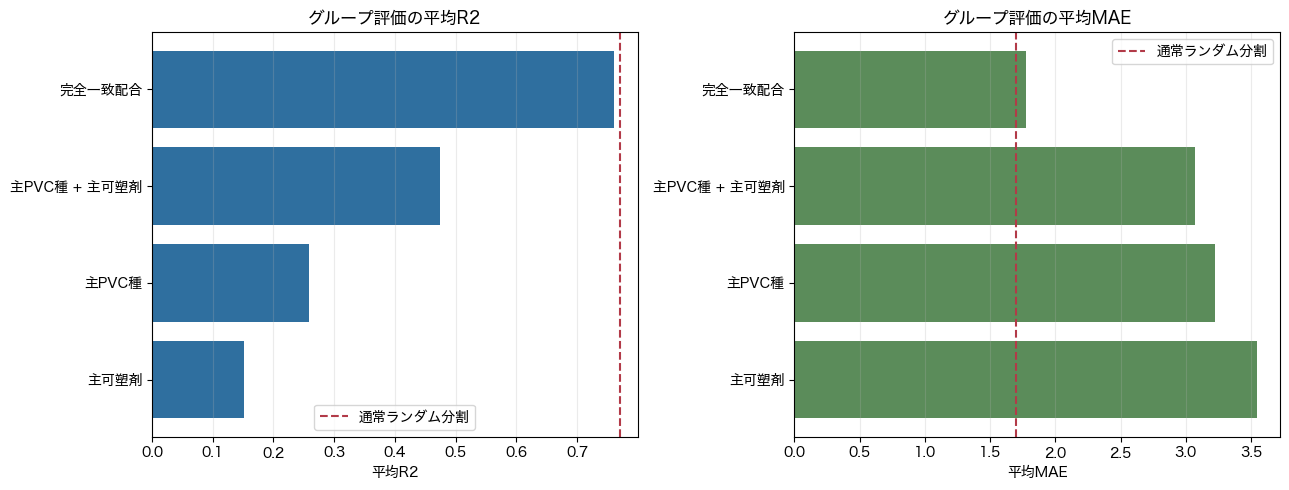

In [5]:
plot_df = summary_metrics.sort_values("mean_R2")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].barh(plot_df["grouping_label"], plot_df["mean_R2"], color="#2f6f9f")
axes[0].axvline(baseline_rf["R2"], color="#b23a48", linestyle="--", label="通常ランダム分割")
axes[0].set_xlabel("平均R2")
axes[0].set_title("グループ評価の平均R2")
axes[0].legend()
axes[0].grid(axis="x", alpha=0.25)

axes[1].barh(plot_df["grouping_label"], plot_df["mean_MAE"], color="#5b8c5a")
axes[1].axvline(baseline_rf["MAE"], color="#b23a48", linestyle="--", label="通常ランダム分割")
axes[1].set_xlabel("平均MAE")
axes[1].set_title("グループ評価の平均MAE")
axes[1].legend()
axes[1].grid(axis="x", alpha=0.25)

fig.tight_layout()
plt.show()


## 分割ごとのばらつき

グループ評価では、どのグループが評価側に入るかで性能が変わります。箱ひげ図でばらつきを確認します。


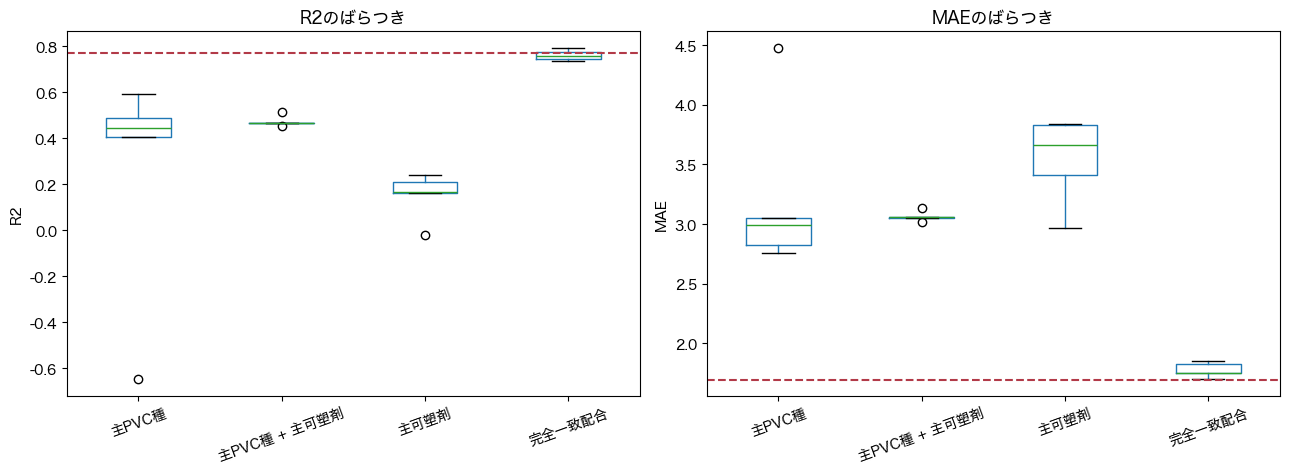

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
order = list(GROUPINGS.keys())

metrics_df.boxplot(column="R2", by="grouping_label", ax=axes[0], grid=False, rot=20)
axes[0].axhline(baseline_rf["R2"], color="#b23a48", linestyle="--")
axes[0].set_title("R2のばらつき")
axes[0].set_xlabel("")
axes[0].set_ylabel("R2")

metrics_df.boxplot(column="MAE", by="grouping_label", ax=axes[1], grid=False, rot=20)
axes[1].axhline(baseline_rf["MAE"], color="#b23a48", linestyle="--")
axes[1].set_title("MAEのばらつき")
axes[1].set_xlabel("")
axes[1].set_ylabel("MAE")

fig.suptitle("")
fig.tight_layout()
plt.show()


## グループ数とグループサイズ

グループ数が少なすぎたり、巨大なグループがある場合、評価は不安定になります。


In [7]:
group_size_summary = (
    group_summary_df.groupby("grouping_label")
    .agg(
        groups=("group", "size"),
        rows=("rows", "sum"),
        min_group_size=("rows", "min"),
        median_group_size=("rows", "median"),
        mean_group_size=("rows", "mean"),
        max_group_size=("rows", "max"),
    )
    .sort_values("groups", ascending=False)
)

display(group_size_summary)

for label in GROUPINGS:
    print()
    print(label)
    display(group_summary_df[group_summary_df["grouping_label"] == label].head(15))


,groups,rows,min_group_size,median_group_size,mean_group_size,max_group_size
grouping_label,,,,,,
完全一致配合,3639,3930,1,1.0,1.079967,10
主PVC種 + 主可塑剤,223,3930,1,3.0,17.623318,554
主可塑剤,39,3930,1,7.0,100.769231,1787
主PVC種,35,3930,1,8.0,112.285714,1306



完全一致配合


,group,rows,row_rate,grouping_label,group_by
0,1747397034179963732,10,0.002545,完全一致配合,exact_composition
1,8984652097547994918,7,0.001781,完全一致配合,exact_composition
2,16993942783947501855,5,0.001272,完全一致配合,exact_composition
3,2450137603215995598,5,0.001272,完全一致配合,exact_composition
4,17137760023345068408,4,0.001018,完全一致配合,exact_composition
5,1984559180281301787,4,0.001018,完全一致配合,exact_composition
6,5629744605962509632,4,0.001018,完全一致配合,exact_composition
7,5814929525465053919,4,0.001018,完全一致配合,exact_composition
8,1075514724151799420,4,0.001018,完全一致配合,exact_composition
9,7814739896175383647,4,0.001018,完全一致配合,exact_composition



主PVC種


,group,rows,row_rate,grouping_label,group_by
3639,PVC1300 / TH1300(JG) (PVC.23),1306,0.332316,主PVC種,primary_pvc
3640,PVC1000 / TH1000(GW) (PVC.15),930,0.236641,主PVC種,primary_pvc
3641,PVC1300 / TH1400(KG) (PVC.24),409,0.104071,主PVC種,primary_pvc
3642,PVC2000 / TH2000(SW) (PVC.30),262,0.066667,主PVC種,primary_pvc
3643,PVC800 / TH800(DJ) (PVC.38),251,0.063868,主PVC種,primary_pvc
3644,PVC2251- / TH2500(SG) (PVC.32),239,0.060814,主PVC種,primary_pvc
3645,PVC700 / TH700(BK) (PVC.35),127,0.032316,主PVC種,primary_pvc
3646,PVC2251- / TH2800(SN) (PVC.33),93,0.023664,主PVC種,primary_pvc
3647,(no PVC),63,0.016031,主PVC種,primary_pvc
3648,架橋PVC2251- / TU300(UA) (PVC.54),55,0.013995,主PVC種,primary_pvc



主可塑剤


,group,rows,row_rate,grouping_label,group_by
3674,フタル酸エステル系 / DOP (可塑剤オイル類.29),1787,0.454707,主可塑剤,primary_plasticizer
3675,フタル酸エステル系 / DINP (可塑剤オイル類.30),1141,0.290331,主可塑剤,primary_plasticizer
3676,トリメリット酸系 / TOTM (可塑剤オイル類.24),372,0.094656,主可塑剤,primary_plasticizer
3677,フタル酸エステル系 / DIDP (可塑剤オイル類.31),122,0.031043,主可塑剤,primary_plasticizer
3678,ポリアジピン酸系 / ポリサイザW2350 (可塑剤オイル類.39),72,0.018321,主可塑剤,primary_plasticizer
3679,ポリアジピン酸系 / ポリサイザW2050 (可塑剤オイル類.41),60,0.015267,主可塑剤,primary_plasticizer
3680,ポリアジピン酸系 / アデカPN7550(D) (可塑剤オイル類.38),58,0.014758,主可塑剤,primary_plasticizer
3681,エポキシ化大豆油 / S300K (可塑剤オイル類.17),54,0.013740,主可塑剤,primary_plasticizer
3682,フタル酸エステル系 / DUP (可塑剤オイル類.33),43,0.010941,主可塑剤,primary_plasticizer
3683,フタル酸エステル系 / ビニサイザ85 (可塑剤オイル類.34),27,0.006870,主可塑剤,primary_plasticizer



主PVC種 + 主可塑剤


,group,rows,row_rate,grouping_label,group_by
3713,PVC1000 / TH1000(GW) (PVC.15) + フタル酸エステル系 / DOP (可塑剤オイル類.29),554,0.140967,主PVC種 + 主可塑剤,primary_pvc_plus_primary_plasticizer
3714,PVC1300 / TH1300(JG) (PVC.23) + フタル酸エステル系 / DOP (可塑剤オイル類.29),531,0.135115,主PVC種 + 主可塑剤,primary_pvc_plus_primary_plasticizer
3715,PVC1300 / TH1300(JG) (PVC.23) + フタル酸エステル系 / DINP (可塑剤オイル類.30),466,0.118575,主PVC種 + 主可塑剤,primary_pvc_plus_primary_plasticizer
3716,PVC1000 / TH1000(GW) (PVC.15) + フタル酸エステル系 / DINP (可塑剤オイル類.30),220,0.055980,主PVC種 + 主可塑剤,primary_pvc_plus_primary_plasticizer
3717,PVC800 / TH800(DJ) (PVC.38) + フタル酸エステル系 / DOP (可塑剤オイル類.29),169,0.043003,主PVC種 + 主可塑剤,primary_pvc_plus_primary_plasticizer
3718,PVC1300 / TH1400(KG) (PVC.24) + フタル酸エステル系 / DOP (可塑剤オイル類.29),152,0.038677,主PVC種 + 主可塑剤,primary_pvc_plus_primary_plasticizer
3719,PVC1300 / TH1300(JG) (PVC.23) + トリメリット酸系 / TOTM (可塑剤オイル類.24),124,0.031552,主PVC種 + 主可塑剤,primary_pvc_plus_primary_plasticizer
3720,PVC1300 / TH1400(KG) (PVC.24) + フタル酸エステル系 / DINP (可塑剤オイル類.30),108,0.027481,主PVC種 + 主可塑剤,primary_pvc_plus_primary_plasticizer
3721,PVC2251- / TH2500(SG) (PVC.32) + フタル酸エステル系 / DOP (可塑剤オイル類.29),102,0.025954,主PVC種 + 主可塑剤,primary_pvc_plus_primary_plasticizer
3722,PVC2000 / TH2000(SW) (PVC.30) + フタル酸エステル系 / DOP (可塑剤オイル類.29),99,0.025191,主PVC種 + 主可塑剤,primary_pvc_plus_primary_plasticizer


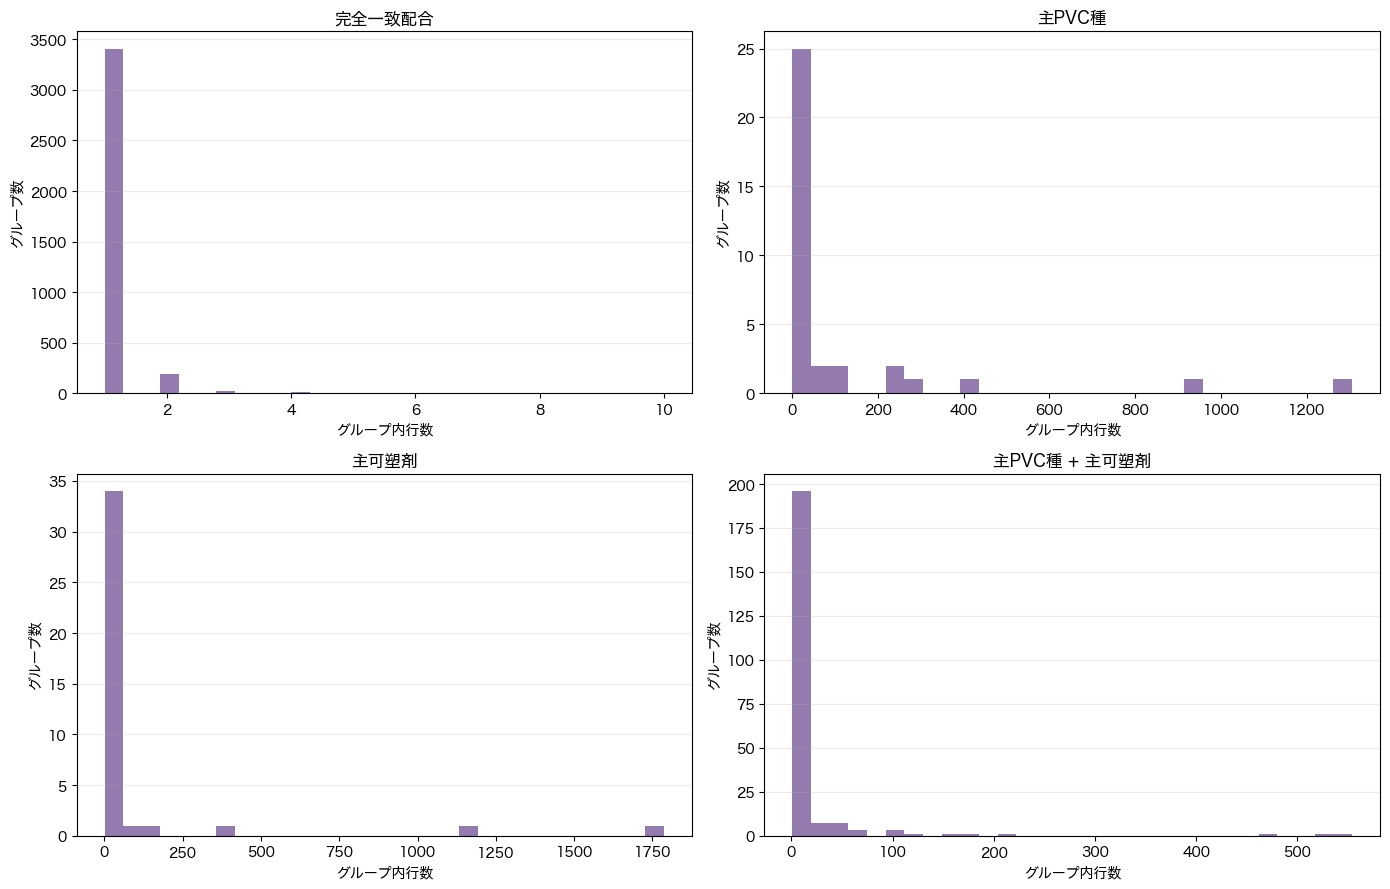

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.ravel()

for ax, label in zip(axes, GROUPINGS.keys()):
    sizes = group_summary_df[group_summary_df["grouping_label"] == label]["rows"]
    ax.hist(sizes, bins=30, color="#8064a2", alpha=0.85)
    ax.set_title(label)
    ax.set_xlabel("グループ内行数")
    ax.set_ylabel("グループ数")
    ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()


## このNotebookでの判断ポイント

- 完全一致配合グループで性能が大きく落ちなければ、完全重複による評価漏洩は小さい
- 主PVC種や主可塑剤で性能が大きく落ちるなら、未知材料系列への外挿はまだ弱い
- 主PVC種 + 主可塑剤は、実務上の配合系列に近いが、グループが細かくなりすぎる可能性がある
- LightGBM/XGBoostへ進む前に、どの評価方法を主指標にするか決める
